In [1]:
from src.utils.RateLimiter import RateLimiter, retry_on_not_ready
import os 
import pandas as pd
import json
import time
targetdate = '2020-04-01'

#### 初始化engine

In [2]:
from src.config import RAM_PATH
from src.factor_engine.engine import FactorEngine
if globals().get("engine", None) is None:
    engine = FactorEngine(
        qlib_data_path=RAM_PATH,
        instrument="all",
        start_time='2020-01-01',
        end_time='2020-12-31',
        
        device="cpu",               # 支援 "cpu" / "cuda:0" 字串或 torch.device
        max_backtrack_days=0,
        max_future_days=0,
        adjust_factor = 'back'
    )
    df_tradable = engine.load_raw_df("$is_tradable")
    tej_df = engine.load_raw_df(['$open' , '$high' , '$low' , '$close' , '$volume' , '$is_tradable'])


data path: /dev/shm/qlib_ram


[136055:MainThread](2026-03-07 22:14:39,193) INFO - qlib.Initialization - [config.py:452] - default_conf: client.
[136055:MainThread](2026-03-07 22:14:39,497) INFO - qlib.Initialization - [__init__.py:82] - qlib successfully initialized based on client settings.
[136055:MainThread](2026-03-07 22:14:39,498) INFO - qlib.Initialization - [__init__.py:84] - data_path={'__DEFAULT_FREQ': PosixPath('/dev/shm/qlib_ram')}


[FactorEngine] Loading data: instrument=all, period=[2020-01-01, 2020-12-31], device=cpu
[FactorEngine] Data loaded: 245 days, 1740 stocks, 10 features, tensor shape=(245, 10, 1740)


#### 獲取當天成交量不為0的所有數據 ，這裡的is_tradable 可能有誤 暫時不刪

In [3]:
# 要檢查這些欄位有沒有 NaN
fields_to_check = ['$open', '$high', '$low', '$close', '$volume']

tej_df_on_targetdate = tej_df.loc[targetdate]

# 找出這些欄位哪些 row 有 NaN
mask_has_na = tej_df_on_targetdate[fields_to_check].isna().any(axis=1)
na_rows = tej_df_on_targetdate[mask_has_na]
not_na_rows = tej_df_on_targetdate[~mask_has_na]

print("=== 有 NaN 欄位的紀錄 ===")
display(na_rows)

print("\n=== 沒有 NaN 欄位的紀錄 ===")
display(not_na_rows)
# 再篩掉成交量為0的股票
not_na_nonzero_volume = not_na_rows[not_na_rows['$volume'] != 0]
print("\n=== 沒有 NaN 且成交量不為0的紀錄 ===")
display(not_na_nonzero_volume)

=== 有 NaN 欄位的紀錄 ===


,$open,$high,$low,$close,$volume,$is_tradable
instrument,,,,,,
3219,NaN,NaN,NaN,NaN,NaN,NaN



=== 沒有 NaN 欄位的紀錄 ===


,$open,$high,$low,$close,$volume,$is_tradable
instrument,,,,,,
1101,39.500000,39.549999,39.000000,39.000000,12970.0,1.0
1102,39.500000,39.599998,38.599998,38.599998,10980.0,1.0
1103,15.150000,15.150000,14.900000,15.100000,1168.0,1.0
1104,15.750000,15.800000,15.550000,15.750000,283.0,1.0
1108,6.310000,6.530000,6.310000,6.500000,168.0,1.0
...,...,...,...,...,...,...
9951,61.099998,61.299999,60.099998,60.900002,136.0,1.0
9955,13.300000,13.550000,13.300000,13.450000,339.0,1.0
9958,77.699997,79.199997,77.000000,78.900002,7059.0,1.0



=== 沒有 NaN 且成交量不為0的紀錄 ===


,$open,$high,$low,$close,$volume,$is_tradable
instrument,,,,,,
1101,39.500000,39.549999,39.000000,39.000000,12970.0,1.0
1102,39.500000,39.599998,38.599998,38.599998,10980.0,1.0
1103,15.150000,15.150000,14.900000,15.100000,1168.0,1.0
1104,15.750000,15.800000,15.550000,15.750000,283.0,1.0
1108,6.310000,6.530000,6.310000,6.500000,168.0,1.0
...,...,...,...,...,...,...
9951,61.099998,61.299999,60.099998,60.900002,136.0,1.0
9955,13.300000,13.550000,13.300000,13.450000,339.0,1.0
9958,77.699997,79.199997,77.000000,78.900002,7059.0,1.0


#### 獲取之前抓到的shioaji數據

In [5]:

one_min_data_folder = '/home/newt/quant_project/1min_data'
from datetime import datetime, timedelta

date_folder= os.path.join(one_min_data_folder , targetdate.replace('-' , ''))
one_min_data = pd.read_parquet(
    os.path.join(date_folder , f"{targetdate.replace('-','')}.parquet")
    )
ts_dt = pd.to_datetime(one_min_data['ts'])
if ts_dt.dt.normalize().nunique() > 1:
    print(f"one_min_data['ts'] 轉成日期後，unique值超過兩個 (共有 {ts_dt.dt.normalize().nunique()} 個): {ts_dt.dt.normalize().unique()}")
    #raise RuntimeError(f"one_min_data['ts'] 轉成日期後，unique值超過兩個 (共有 {ts_dt.dt.normalize().nunique()} 個): {ts_dt.dt.normalize().unique()}")
    # 依據日期拆分 one_min_data，分別儲存為各自日期的檔案
    # 取得所有 ts 唯一的日期（normalize 後，轉字串 yyyymmdd）
    all_dates = ts_dt.dt.normalize().unique()
    for dt in all_dates:
        date_str = dt.strftime('%Y%m%d')
        # 過濾出該日期的一分鐘資料
        mask = ts_dt.dt.normalize() == dt
        data_on_day = one_min_data[mask]
        # 檔案路徑
        out_folder = os.path.join(one_min_data_folder, date_str)
        if os.path.exists(out_folder):
            print(f"路徑已存在: {out_folder} 跳過")
            continue
        os.makedirs(out_folder, exist_ok=True)
        out_path = os.path.join(out_folder, f"{date_str}.parquet")
        data_on_day.to_parquet(out_path, index=False)
        print(f"已儲存當日 one_min_data : {out_path}")
# ts 可能是 datetime，用日期比較過濾當日資料
ts_dt = pd.to_datetime(one_min_data['ts'])
one_min_data = one_min_data[ts_dt.dt.normalize() == pd.Timestamp(targetdate).normalize()]


one_min_data.head()
# 根據 code 分組，計算 Volume 總和，篩掉總和為 0 的 code
vol_sum_by_code = one_min_data.groupby('code')['Volume'].sum()
valid_codes = vol_sum_by_code[vol_sum_by_code != 0].index
one_min_data = one_min_data[one_min_data['code'].isin(valid_codes)]
error_json_path = os.path.join(date_folder, f"{targetdate.replace('-','')}error.json")
with open(error_json_path, "r") as f:
    err_codes = json.load(f)
if err_codes:
    print(f"⚠️ 偵測到 error.json 有內容：{err_codes}")
    raise RuntimeError("err_codes 非空，請檢查錯誤記錄，終止執行")

##### 獲取和tej數據不匹配的資料

In [6]:
# 取出兩邊的 code 集合（一律轉成字串並去前後空白，確保比對都是文字）
codes_tej = set(str(x).strip() for x in not_na_nonzero_volume.index)
codes_one_min = set(one_min_data["code"].astype(str).str.strip().unique())

# A(tej) 有、B(one_min) 沒有
only_in_tej = codes_tej - codes_one_min
# B(one_min) 有、A(tej) 沒有
only_in_one_min = codes_one_min - codes_tej

print(f"not_na_nonzero_volume 筆數: {len(codes_tej)}")
print(f"one_min_data 不重複 code 數: {len(codes_one_min)}")
print(f"---")
print(f"僅在 TEJ: {len(only_in_tej)} 個 → {sorted(only_in_tej)[:20]}{' ...' if len(only_in_tej) > 20 else ''}")
print(f"僅在 one_min: {len(only_in_one_min)} 個 → {sorted(only_in_one_min)[:20]}{' ...' if len(only_in_one_min) > 20 else ''}")
print(f"兩邊都有: {len(codes_tej & codes_one_min)} 個")

not_na_nonzero_volume 筆數: 1673
one_min_data 不重複 code 數: 1608
---
僅在 TEJ: 65 個 → ['1258', '1333', '1507', '1592', '1701', '1724', '1902', '2358', '2443', '2448', '2456', '2499', '2809', '2823', '2841', '2888', '2928', '2936', '3089', '3144'] ...
僅在 one_min: 0 個 → []
兩邊都有: 1608 個


In [6]:
if only_in_one_min:
    raise ValueError ('有code 只在one_min')

In [10]:
df_out = one_min_data[one_min_data['code']=='1805']
df_out.to_csv('/home/newt/quant_project/1101_test.csv')

TEJ 總共 code 數：1608
不一致的 code 數：1578
各欄位不一致的筆數：
  Open: 36
  High: 0
  Low: 36
  Close: 0
  Volume: 1576
不完全相同的 code 有： ['1101', '1102', '1103', '1104', '1108', '1109', '1110', '1201', '1203', '1210', '1213', '1215', '1216', '1217', '1218', '1219', '1220', '1225', '1227', '1229', '1231', '1232', '1233', '1234', '1235', '1236', '1240', '1256', '1259', '1264', '1268', '1301', '1303', '1304', '1305', '1307', '1308', '1309', '1310', '1312', '1313', '1314', '1315', '1316', '1319', '1321', '1323', '1324', '1325', '1326', '1336', '1337', '1338', '1339', '1340', '1341', '1402', '1409', '1410', '1413', '1414', '1417', '1419', '1423', '1432', '1434', '1435', '1436', '1437', '1439', '1440', '1442', '1443', '1444', '1445', '1446', '1447', '1449', '1451', '1452', '1453', '1454', '1455', '1456', '1457', '1459', '1460', '1463', '1464', '1465', '1466', '1467', '1468', '1471', '1472', '1473', '1474', '1475', '1476', '1477', '1504', '1506', '1512', '1513', '1514', '1515', '1516', '1517', '1519', '1521', 

,Open,High,Low,Close,Volume
code,,,,,
1101,39.50,39.55,39.00,39.00,14616.0
1102,39.50,39.60,38.60,38.60,11976.0
1103,15.15,15.15,14.90,15.10,1226.0
1104,15.75,15.80,15.55,15.75,288.0
1108,6.31,6.53,6.31,6.50,181.0
...,...,...,...,...,...
9951,61.10,61.30,60.10,60.90,145.0
9955,13.30,13.55,13.30,13.45,343.0
9958,77.70,79.20,77.00,78.90,7353.0


TEJ 日K（僅列不同）：


,Open,High,Low,Close,Volume
code,,,,,
1101,39.50,39.55,39.00,39.00,12970.0
1102,39.50,39.60,38.60,38.60,10980.0
1103,15.15,15.15,14.90,15.10,1168.0
1104,15.75,15.80,15.55,15.75,283.0
1108,6.31,6.53,6.31,6.50,168.0
...,...,...,...,...,...
9951,61.10,61.30,60.10,60.90,136.0
9955,13.30,13.55,13.30,13.45,339.0
9958,77.70,79.20,77.00,78.90,7059.0


/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 22810 (\N{CJK UNIFIED IDEOGRAPH-591A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 23569 (\N{CJK UNIFIED IDEOGRAPH-5C11}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 24046 (\N{CJK UNIFIED IDEOGRAPH-5DEE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 30064 (\N{CJK UNIFIED IDEOGRAPH-7570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_136055/3221979540.py:125: UserWarning: Glyph 30334 (\N{CJK UN

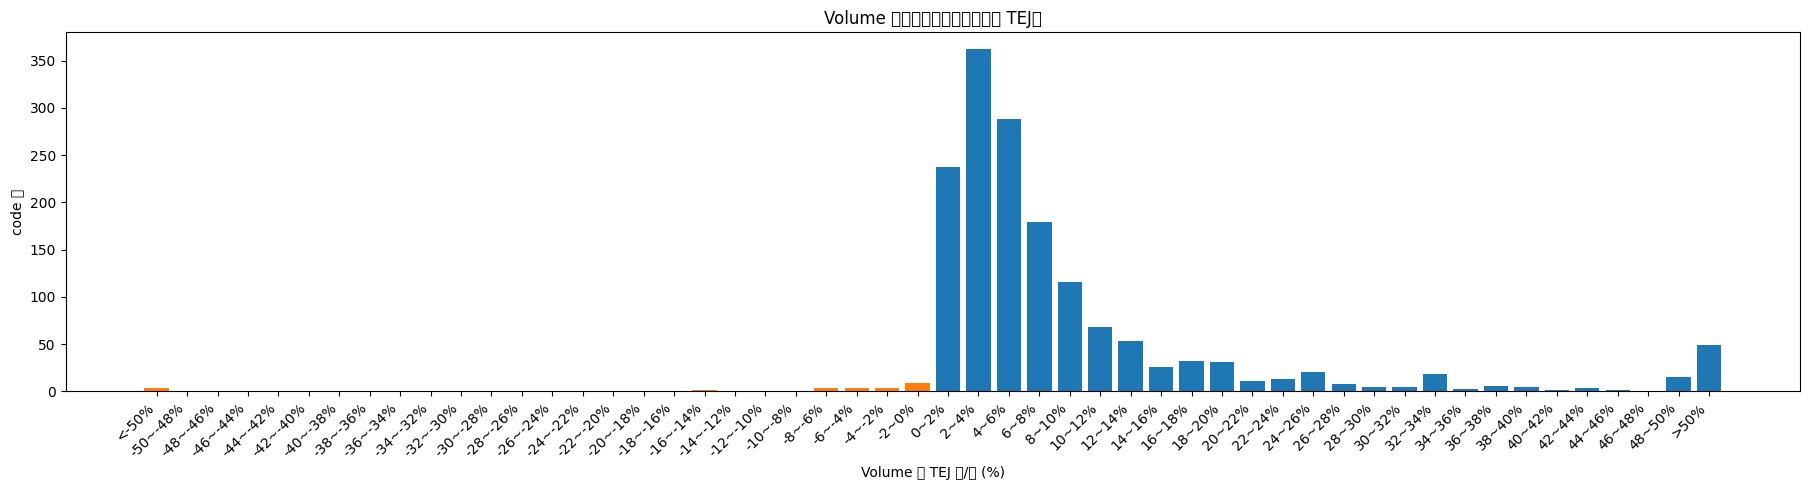

In [8]:
# 把 one_min_data 以 code 聚合成一天的日K（同not_na_nonzero_volume的格式），並格式統一為 float (OHLCV)
ohlcv_cols = ["Open", "High", "Low", "Close", "Volume"]
# 先複製資料並確保正確型別
one_min_agg = one_min_data.copy()
# 若有用戶自訂欄名則處理
one_min_agg = one_min_agg.rename(columns={
    "Open": "Open",
    "High": "High",
    "Low": "Low",
    "Close": "Close",
    "Volume": "Volume"
})
# 確保型別一致
for col in ohlcv_cols:
    one_min_agg[col] = pd.to_numeric(one_min_agg[col], errors="coerce").astype(float)

# 聚合函數
agg_funcs = {
    "Open": "first",
    "High": "max",
    "Low": "min",
    "Close": "last",
    "Volume": "sum"
}
one_min_dayk = one_min_agg.groupby("code").agg(agg_funcs)
one_min_dayk = one_min_dayk[ohlcv_cols]  # 只保留相關欄位

# not_na_nonzero_volume 來自 qlib/TEJ，欄位為 $open, $high, $low, $close, $volume；轉成 Open, High, Low, Close, Volume 與 one_min 一致
tej_ohlcv = ["$open", "$high", "$low", "$close", "$volume"]
not_na_dayk = not_na_nonzero_volume.copy()
for i, col in enumerate(ohlcv_cols):
    not_na_dayk[col] = pd.to_numeric(not_na_dayk[tej_ohlcv[i]], errors="coerce").astype(float)
not_na_dayk = not_na_dayk[ohlcv_cols]

# index 統一轉 str 方便比對
one_min_dayk.index = one_min_dayk.index.astype(str)
not_na_dayk.index = not_na_dayk.index.astype(str)

# 兩個 dataframe 對 index 做 inner join 排序統一
idx_inter = sorted(set(one_min_dayk.index) & set(not_na_dayk.index))
one_min_k_matched = one_min_dayk.loc[idx_inter].copy()
not_na_k_matched = not_na_dayk.loc[idx_inter].copy()

# 依台股 tick 規則對 OHLC 四捨五入，小數位嚴格遵守
from decimal import Decimal, ROUND_HALF_UP

def _tick_for_price(raw_price_float):
    if raw_price_float < 10:
        return Decimal('0.01'), 2
    elif raw_price_float < 50:
        return Decimal('0.05'), 2
    elif raw_price_float < 100:
        return Decimal('0.1'), 1
    elif raw_price_float < 500:
        return Decimal('0.5'), 1
    elif raw_price_float < 1000:
        return Decimal('1.0'), 0
    else:
        return Decimal('5.0'), 0

def round_to_tick(price):
    if pd.isna(price):
        return price
    raw = float(price)
    tick, places = _tick_for_price(raw)
    d = Decimal(str(raw))
    rounded = (d / tick).quantize(Decimal('1'), rounding=ROUND_HALF_UP) * tick
    q = Decimal('1') if places == 0 else Decimal('0.1') ** places
    return float(rounded.quantize(q, rounding=ROUND_HALF_UP))

ohlc_cols = ["Open", "High", "Low", "Close"]
for df in (one_min_k_matched, not_na_k_matched):
    for c in ohlc_cols:
        df[c] = df[c].apply(round_to_tick)

# 比較完全一樣性
tej_total = len(not_na_k_matched)
diff_mask = ~(one_min_k_matched == not_na_k_matched)
diff_codes = one_min_k_matched.index[diff_mask.any(axis=1)]
diff_count = len(diff_codes)

print(f"TEJ 總共 code 數：{tej_total}")
print(f"不一致的 code 數：{diff_count}")

# 各欄位出錯數量
print("各欄位不一致的筆數：")
for col in ohlcv_cols:
    n = int(diff_mask[col].sum())
    print(f"  {col}: {n}")
if diff_count > 0:
    print("不完全相同的 code 有：", list(diff_codes))
    print("one_min 聚合日K（僅列不同）：")
    display(one_min_k_matched.loc[diff_codes])
    print("TEJ 日K（僅列不同）：")
    display(not_na_k_matched.loc[diff_codes])
else:
    print("one_min 聚合日K 和 not_na_nonzero_volume 完全一致！")

    
# Volume 差異分布：橫軸=差異百分比區間，縱軸=落在該區間的 code 數
volume_diff_codes = one_min_k_matched.index[diff_mask["Volume"]].tolist()
if len(volume_diff_codes) > 0:
    one_vol = one_min_k_matched.loc[volume_diff_codes, "Volume"]
    tej_vol = not_na_k_matched.loc[volume_diff_codes, "Volume"]
    pct_diff = (one_vol - tej_vol) / tej_vol.replace(0, float("nan")) * 100
    pct_diff = pct_diff.fillna(0)
    import matplotlib.pyplot as plt
    import numpy as np
    # 分箱：每 2% 一區間（-50%～50%，以外歸類 <−50% / >50%）
    bin_edges = list(np.arange(-50, 52, 2))
    bins = [-np.inf] + bin_edges + [np.inf]
    labels = ["<-50%"] + [f"{int(b)}~{int(b)+2}%" for b in np.arange(-50, 50, 2)] + [">50%"]
    pct_binned = pd.cut(pct_diff, bins=bins, labels=labels)
    counts = pct_binned.value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(max(12, len(counts) * 0.35), 5))
    x_pos = range(len(counts))
    n_neg = sum(1 for lb in counts.index if str(lb).startswith("-") or lb == "<-50%")
    colors = ["C1" if i < n_neg else "C0" for i in range(len(counts))]
    ax.bar(x_pos, counts.values, color=colors)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(counts.index, rotation=45, ha="right")
    ax.set_ylabel("code 數")
    ax.set_xlabel("Volume 較 TEJ 多/少 (%)")
    ax.set_title("Volume 差異百分比分布（相對於 TEJ）")
    plt.tight_layout()
    plt.show()
else:
    print("Volume 無不一致，略過柱狀圖。")



In [9]:
# 抓出 Open High Low Close 不同的資料
diff_ohlc_mask = diff_mask[["Open", "High", "Low", "Close"]].any(axis=1)
diff_ohlc_codes = one_min_k_matched.index[diff_ohlc_mask].tolist()

if diff_ohlc_codes:
    print("Open/High/Low/Close 不同的 code 有：", diff_ohlc_codes)
    print("one_min 聚合日K（僅列 OHLC 不同）：")
    display(one_min_k_matched.loc[diff_ohlc_codes, ["Open", "High", "Low", "Close"]])
    print("TEJ 日K（僅列 OHLC 不同）：")
    display(not_na_k_matched.loc[diff_ohlc_codes, ["Open", "High", "Low", "Close"]])
else:
    print("所有 code 的 Open/High/Low/Close 欄位皆一致。")

Open/High/Low/Close 不同的 code 有： ['1805', '2434', '2438', '2440', '2540', '3011', '3073', '3162', '3207', '3230', '3288', '3308', '3465', '3593', '4198', '4556', '4737', '4804', '4806', '4907', '4950', '5276', '5314', '5344', '5345', '5381', '5484', '6144', '6246', '6264', '6418', '6574', '6629', '8488', '8929', '9929']
one_min 聚合日K（僅列 OHLC 不同）：


,Open,High,Low,Close
code,,,,
1805,0.0,8.52,0.0,8.20
2434,0.0,5.49,0.0,5.30
2438,0.0,5.68,0.0,5.55
2440,0.0,7.88,0.0,7.88
2540,0.0,16.90,0.0,16.90
3011,0.0,4.78,0.0,4.60
3073,0.0,8.80,0.0,8.80
3162,0.0,6.78,0.0,6.78
3207,0.0,10.75,0.0,10.75


TEJ 日K（僅列 OHLC 不同）：


,Open,High,Low,Close
instrument,,,,
1805,8.21,8.52,8.18,8.20
2434,5.20,5.49,5.20,5.30
2438,5.29,5.68,5.28,5.55
2440,7.31,7.88,7.31,7.88
2540,16.40,16.90,16.40,16.90
3011,4.78,4.78,4.28,4.60
3073,8.50,8.80,8.50,8.80
3162,6.77,6.78,6.77,6.78
3207,10.50,10.75,10.25,10.75


In [ ]:
from src.utils.RateLimiter import RateLimiter, retry_on_not_ready
rate_limiter = RateLimiter(max_requests=45, time_window=5)
@retry_on_not_ready(max_retries=3, delay=2, rate_limiter=rate_limiter)
def fetch_kbars_with_retry(api, code, start_date, end_date):
    """帶重試機制和速率限制的 kbars 請求"""    
    kbars = api.kbars(
        contract=api.Contracts.Stocks[code],
        start=start_date,
        end=end_date,
    )
    return kbars
API_KEY = "BUe3s2QFD6Amkdt1F6t6sRyKBMAfk9ruS1HFvYQ1r8np"
SECRET_KEY = "AoeSQjaLEtquhrtsjNGZRbTVzXSVKCJCPy8Afn3oaSSU"
import shioaji as sj
import pandas as pd
from datetime import datetime, timedelta
import time
from tqdm import tqdm
import os

if globals().get("global_api", None) is None:
    global_api = sj.Shioaji(simulation=True)
    global_api.login(
        api_key=API_KEY ,
        secret_key=SECRET_KEY ,
        fetch_contract=True
    )
target_date = targetdate
target_date_obj = datetime.strptime(target_date, '%Y-%m-%d').date()
next_date_obj = target_date_obj + timedelta(days=1)
next_date_str = next_date_obj.strftime('%Y-%m-%d')
print(target_date ,next_date_str)

In [ ]:
from tqdm import tqdm
fail_task = []
result_df_list =[]
no_trade_record = []
instruments_copy = list(only_in_tej.copy())

if len(instruments_copy) > 0 :
    with tqdm(total=len(instruments_copy), desc=f"日期: {target_date}", unit="筆") as pbar:
        while len(instruments_copy) > 0 :
            code = instruments_copy.pop(0)
            try:

                kbars = fetch_kbars_with_retry(
                global_api, 
                code, 
                target_date,
                next_date_str
                )
                df = pd.DataFrame({**kbars})
                df.ts = pd.to_datetime(df.ts)
                # 把這裡的ts轉成文字 看看是不是target_date
                if not df.empty:
                    ts_str_first = df.ts.iloc[0].strftime('%Y-%m-%d')
                    if ts_str_first != target_date:
                        raise ValueError(f"第一筆 ts ({ts_str_first}) 和 target_date ({target_date}) 不一致，code: {code}")
                
                if df.empty:
                    no_trade_record.append(code)
                df['code'] = code
                result_df_list.append(df)
            except Exception as e :
                if "'NoneType' object has no attribute 'dict'" in str(e):
                    fail_task.append(code)
                else:
                    print(e)
            finally :
                pbar.update(1)
df_result = pd.concat(result_df_list)
print(f'fail 數量 {len(fail_task)}')
display(fail_task[:5])
print(f'no_trade_record 數量 {len(no_trade_record)}')
display(no_trade_record)

## 從FinMind 獲取數據

In [11]:
from src.config import FINMIND_TOKEN
from FinMind.data import DataLoader
from loguru import logger
import sys
logger.remove()  # 移除預設 handler
logger.add(sys.stderr, level="WARNING")
finmind_api = DataLoader()
finmind_api.login_by_token(api_token=FINMIND_TOKEN)

True

In [ ]:
finMind_fetch_codes  = list(codes_tej.copy())
rate_limiter_finmind = RateLimiter(max_requests=97, time_window=60)
@retry_on_not_ready(max_retries=3, delay=2, rate_limiter=rate_limiter_finmind)
def fetch_data_finmind(api, code, date):
    """帶重試機制和速率限制的 kbars 請求"""    
    return api.taiwan_stock_kbar(
        stock_id=code,
        date=date
    )

In [ ]:
finmind_single_day = finmind_api.taiwan_stock_daily(
    start_date=targetdate,
)
finmind_single_day[finmind_single_day['stock_id']=='1101']

In [12]:
df_tmp = finmind_api.taiwan_stock_kbar(
        stock_id='1805',
        date=targetdate
    )
df_tmp.to_csv('/home/newt/quant_project/1805_finmind.csv')

In [ ]:
# # 取出兩邊的 code 集合（一律轉成字串並去前後空白，確保比對都是文字）
# codes_tej = set(str(x).strip() for x in not_na_nonzero_volume.index)
# codes_finMind = set(result_finmind["stock_id"].astype(str).str.strip().unique())

# # A(tej) 有、B(one_min) 沒有
# only_in_tej = codes_tej - codes_finMind
# # B(one_min) 有、A(tej) 沒有
# only_in_one_min = codes_finMind - codes_tej

# print(f"not_na_nonzero_volume 筆數: {len(codes_tej)}")
# print(f"codes_finMind 不重複 code 數: {len(codes_finMind)}")
# print(f"---")
# print(f"僅在 TEJ: {len(only_in_tej)} 個 → {sorted(only_in_tej)[:20]}{' ...' if len(only_in_tej) > 20 else ''}")
# print(f"僅在 finMind: {len(only_in_one_min)} 個 → {sorted(only_in_one_min)[:20]}{' ...' if len(only_in_one_min) > 20 else ''}")
# print(f"兩邊都有: {len(codes_tej & codes_finMind)} 個")

In [ ]:
code = '8287'
df=finmind_api.taiwan_stock_kbar(
        stock_id=code,
        date=targetdate
    )
df

In [ ]:
# from tqdm import tqdm
# fail_task = []
# result_df_list =[]
# no_trade_record = []

# if len(finMind_fetch_codes) > 0 :
#     with tqdm(total=len(finMind_fetch_codes), desc=f"日期: {targetdate}", unit="筆") as pbar:
#         while len(finMind_fetch_codes) > 0 :
#             code = finMind_fetch_codes.pop(0)
#             try:

#                 df = fetch_data_finmind(
#                     finmind_api , 
#                     code , 
#                     targetdate
#                 )
#                 if df.empty:
#                     no_trade_record.append(code)
#                 result_df_list.append(df)
#             except Exception as e :
#                 fail_task.append(code)
#                 print(e)
#             finally :
#                 pbar.update(1)
# finmind_result = pd.concat(result_df_list)
# print(f'fail 數量 {len(fail_task)}')
# display(fail_task[:5])
# print(f'no_trade_record 數量 {len(no_trade_record)}')
# display(no_trade_record)

只有tej有的數據 先重新下載一次

In [ ]:
# global_api.logout()
# del global_api

In [ ]:
print(target_date ,next_date_str )

In [ ]:
df_result[df_result['code']=='8406']

In [ ]:
code = '8287'
kbars = fetch_kbars_with_retry(
global_api, 
code, 
target_date,
next_date_str
)
df = pd.DataFrame({**kbars})
df.ts = pd.to_datetime(df.ts)
df['code'] = code
df

In [ ]:
one_min_data = pd.concat([one_min_data , df_result])

In [ ]:
# 取出兩邊的 code 集合（一律轉成字串並去前後空白，確保比對都是文字）
codes_tej = set(str(x).strip() for x in tej_df_on_targetdate.index)
codes_one_min = set(one_min_data["code"].astype(str).str.strip().unique())

# A(tej) 有、B(one_min) 沒有
only_in_tej = codes_tej - codes_one_min
# B(one_min) 有、A(tej) 沒有
only_in_one_min = codes_one_min - codes_tej

print(f"tej_df_on_targetdate 筆數: {len(codes_tej)}")
print(f"one_min_data 不重複 code 數: {len(codes_one_min)}")
print(f"---")
print(f"僅在 TEJ: {len(only_in_tej)} 個 → {sorted(only_in_tej)[:20]}{' ...' if len(only_in_tej) > 20 else ''}")
print(f"僅在 one_min: {len(only_in_one_min)} 個 → {sorted(only_in_one_min)[:20]}{' ...' if len(only_in_one_min) > 20 else ''}")
print(f"兩邊都有: {len(codes_tej & codes_one_min)} 個")

In [ ]:
import pandas as pd

parquet_path = "/home/newt/quant_project/TEJ_processed_data/before_20260123/4114_processed.parquet"
df_4114 = pd.read_parquet(parquet_path)
df_4114_2020 = df_4114[df_4114['date'].astype(str).str.startswith("2020")]
num_2020 = len(df_4114_2020)
print(f"4114 在 2020 年有 {num_2020} 筆數據")

In [ ]:
# 假設 tej_df 已經有 datetime 資訊作為 index（MultiIndex），直接取用
# 會優先找 "date"、再找 "ts" 作為代表的 index
datetime_index_name = None
for candidate in ["date", "ts" , 'datetime']:
    if candidate in tej_df.index.names:
        datetime_index_name = candidate
        break
if datetime_index_name is None:
    raise ValueError("tej_df 的 MultiIndex 中找不到 'date' 或 'ts' 欄位")
date_series = pd.to_datetime(tej_df.index.get_level_values(datetime_index_name))
print("TEJ 全部資料日期範圍：", date_series.min(), "～", date_series.max())

In [ ]:
# 修正：用 str '4114' 比對（qlib instrument index 是字串）

tej_4114 = tej_df[tej_df.index.get_level_values("instrument") == '8287']
print(f"4114 在 tej_df 中共 {len(tej_4114)} 筆")
tej_4114.head(10)

In [ ]:
tej_4114_20200401 = tej_4114[tej_4114.index.get_level_values("datetime") == '2020-04-01']
print(f"4114 在 tej_df 中共 {len(tej_4114_20200401)} 筆")
tej_4114_20200401.head(10)

In [ ]:
code = '4114'
tradable_path = f'/home/newt/quant_project/zip_files_tradable_disposed/{code}_tradable_disposed.parquet'
tradable_df = pd.read_parquet(tradable_path)
tradable_df.head()

In [ ]:
tradable_df[tradable_df['date'] == '2020-04-01']